# Chapter 8: Hierarchical Clustering

In [92]:
%reset
low_memory=False
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
import matplotlib.mlab as mlab
import seaborn as sns; sns.set()
from scipy import stats
import math
import os
import random
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, accuracy_score
from sklearn.datasets import load_digits
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import pairwise_distances_argmin
import scipy.cluster.hierarchy as shc
from scipy.stats import mode


## 8.1 Introduction & Motivation

The $k$ Means algorithm is absolutely awesome in detecting clusters when we know beforehand exactly how many clusters we're going to have. But like we already saw, it becomes a little bit more complicated when we don't know beforehand. We could calculate some kind of metric (like we did), then fit loads of $k$Means models, and compare them all. Or, we could use **Hierarchical Clustering**.

## 8.2 Problem Setting

We're still working with the unsupervised version of the digits dataset. For more information, refer to the previous chapter.

In [93]:
digits = load_digits()
digits.data.shape

(1797, 64)

## 8.3 Model

### 8.3.1 Model

The idea of hierarchical clustering is exceedingly simple. Consider the following dataset:

![](https://s3.amazonaws.com/stackabuse/media/hierarchical-clustering-python-scikit-learn-1.png)

We can obviously see two clusters here, but we need a new algorithm to calculate them. We'll start off by giving each observation its own cluster. Then, we'll calculate the distance between all points/clusters. The two points closest together will merge together into one cluster. We continue this process until we've got all points in 1 cluster. Like that, we have formed a solution for each possible amount of clusters. Graphically, it will look like this: 

![](https://s3.amazonaws.com/stackabuse/media/hierarchical-clustering-python-scikit-learn-2.png)

We can now cut off the tree wherever we want, to end up with a prediction for the exact amount of clusters we desire:

![](https://s3.amazonaws.com/stackabuse/media/hierarchical-clustering-python-scikit-learn-4.png)

### 8.3.2 Model Estimation

We'll start off by fitting the Dendogram:

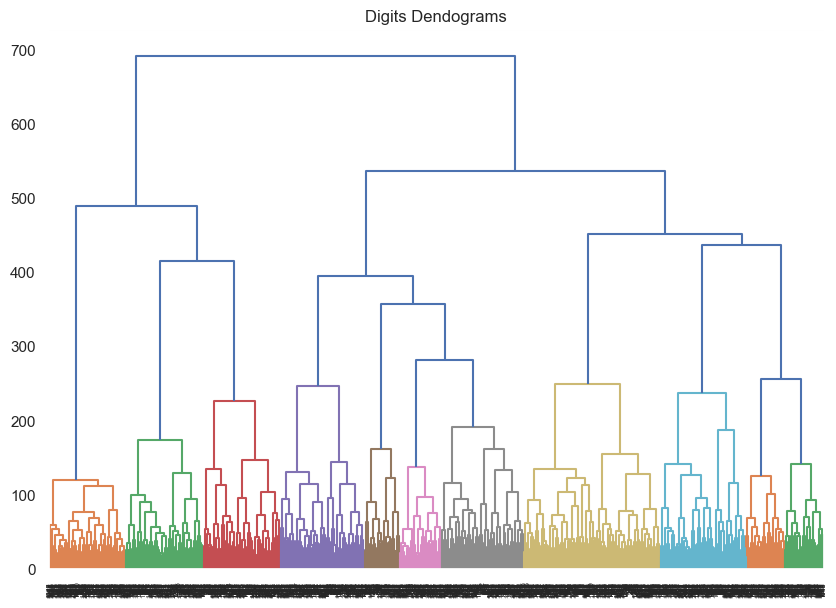

In [94]:
plt.figure(figsize=(10, 7))
plt.title("Digits Dendograms")
Z = shc.linkage(digits.data, method='ward')
dend = shc.dendrogram(Z, color_threshold=250)

#### Question 1: Look at the code above. How do we define the colored clusters? 

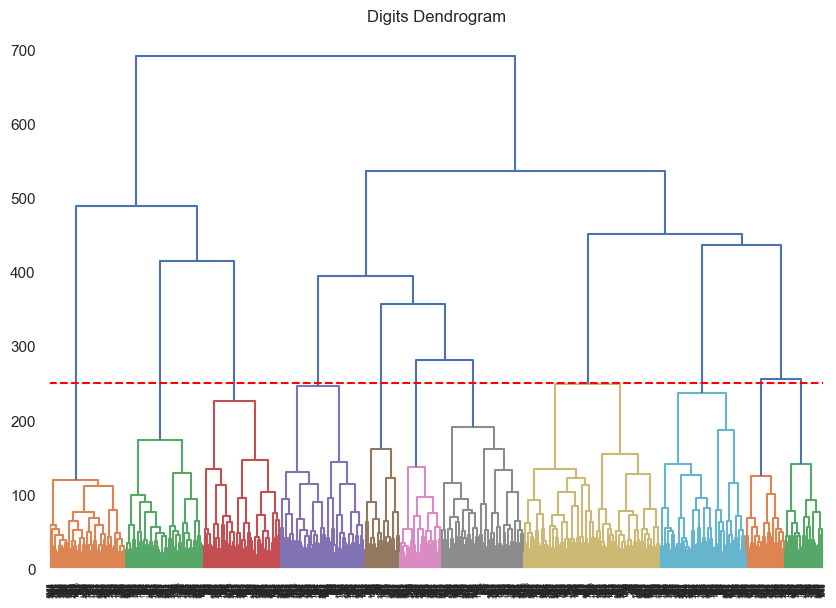

In [95]:
# Answer Question 1:
# De gekleurde clusters worden bepaald met color_threshold.
# Dat is eigenlijk de horizontale lijn waar we de dendrogram 'knippen'.
# Alles onder die lijn krijgt een kleur en stelt een cluster voor.

plt.figure(figsize=(10, 7))
plt.title("Digits Dendrogram")
Z = shc.linkage(digits.data, method='ward')
shc.dendrogram(Z, color_threshold=250)
plt.axhline(y=250, color='red', linestyle='--')
plt.show()


Normally we would draw our line (read: cutoff point) where the largest distance is without merging. We can immediately see why Hierarchical Clustering is so nice. If certain figures look too hard alike, we can simply allow for an additional cluster so it comes out better.

In this case, however, we'll continue by fitting our model for 10 clusters:

In [96]:
cluster = AgglomerativeClustering(n_clusters=10, linkage='ward')
cluster.fit_predict(digits.data)

array([7, 9, 4, ..., 4, 1, 4], shape=(1797,))

## 8.4 Exercises

#### Question 1: See 8.3.2

#### Question 2: Try to fit the elbow plot for the hierarchical clustering model on the digits dataset.

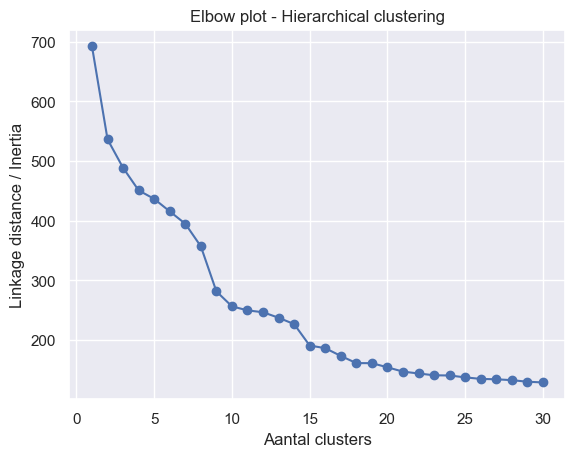

In [97]:
# Bij Ward linkage staat in Z[:, 2] de afstand/inertia van elke samenvoeging.
# De grootste sprongen zijn het interessantst, daarom draaien we de lijst om.

Z = shc.linkage(digits.data, method='ward')
inertia = Z[:, 2]
inertia_reversed = inertia[::-1]

plt.plot(range(1, 31), inertia_reversed[:30], marker='o')
plt.title('Elbow plot - Hierarchical clustering')
plt.xlabel('Aantal clusters')
plt.ylabel('Linkage distance / Inertia')
plt.show()


#### Question 3: Try to split the dataset between test and train and check how accurate the best possible hierarchical clustering model is.

In [98]:
# X = digits.data
# y = digits.target

# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)


# cluster = AgglomerativeClustering(n_clusters=10, linkage='ward')
# clusters = cluster.fit_predict(X_train)


# labels = np.zeros_like(clusters)
# for i in range(10):
#     mask = (clusters == i)
#     labels[mask] = mode(y_train[mask])[0]

# accuracy_score(y_train,labels)




X = digits.data
y = digits.target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0)


hierarchical_model = AgglomerativeClustering(n_clusters=10, linkage='ward')
train_clusters = hierarchical_model.fit_predict(X_train)

# Geef elk cluster een label: het meest voorkomende echte cijfer in dat cluster.
cluster_to_digit = {}
for cluster_id in np.unique(train_clusters):
    real_digits_in_cluster = y_train[train_clusters == cluster_id]
    most_common_digit = np.bincount(real_digits_in_cluster).argmax()
    cluster_to_digit[cluster_id] = most_common_digit

# Bereken het centrum van elk cluster.
cluster_ids = np.array(sorted(cluster_to_digit.keys()))
cluster_centers = np.array([
    X_train[train_clusters == cluster_id].mean(axis=0)
    for cluster_id in cluster_ids
])

# Koppel elke test-observatie aan het dichtstbijzijnde clustercentrum.
nearest_center_index = pairwise_distances_argmin(X_test, cluster_centers)
test_clusters = cluster_ids[nearest_center_index]

# Zet de cluster-nummers om naar voorspelde cijfers.
y_pred_hierarchical = np.array([cluster_to_digit[cluster_id] for cluster_id in test_clusters])

hierarchical_accuracy = accuracy_score(y_test, y_pred_hierarchical)
hierarchical_accuracy


0.7755555555555556

#### Question 4: Compare the hierarchical clustering and the $k$ means clustering algorithm for this dataset. Report. Which one provides the best fit? Is this what you would expect?

In [99]:
# We gebruiken opnieuw 10 clusters zodat de vergelijking eerlijk blijft.

kmeans_model = KMeans(n_clusters=10, random_state=42, n_init=10)
kmeans_train_clusters = kmeans_model.fit_predict(X_train)
kmeans_test_clusters = kmeans_model.predict(X_test)

# Ook bij KMeans moeten we clusters vertalen naar echte cijfers.
kmeans_cluster_to_digit = {}
for cluster_id in np.unique(kmeans_train_clusters):
    real_digits_in_cluster = y_train[kmeans_train_clusters == cluster_id]
    most_common_digit = np.bincount(real_digits_in_cluster).argmax()
    kmeans_cluster_to_digit[cluster_id] = most_common_digit

y_pred_kmeans = np.array([
    kmeans_cluster_to_digit[cluster_id]
    for cluster_id in kmeans_test_clusters
])

kmeans_accuracy = accuracy_score(y_test, y_pred_kmeans)

comparison = pd.DataFrame({
    'Model': ['Hierarchical clustering', 'KMeans clustering'],
    'Accuracy': [hierarchical_accuracy, kmeans_accuracy]
})
comparison


,Model,Accuracy
0,Hierarchical clustering,0.775556
1,KMeans clustering,0.777778


### Report

Ik heb beide modellen getest met 10 clusters, omdat de dataset bestaat uit 10 cijfers: 0 tot en met 9.

Bij hierarchical clustering worden punten stap voor stap samengevoegd tot clusters. In de dendrogram kunnen we zien waar grote sprongen zitten. Zo kunnen we beslissen waar we de boom knippen. Te veel clusters zou overfitting zijn, daarom kiezen we een logisch aantal clusters met de elbow/dendrogram.

Voor de accuracy moest ik de clusters eerst koppelen aan echte cijfers. Een cluster heeft namelijk geen naam zoals "3" of "7". Daarom kreeg elk cluster het cijfer dat er het vaakst in voorkwam.

In deze vergelijking geeft het model met de hoogste accuracy de beste fit. Vaak zal KMeans hier iets beter scoren, omdat de digits dataset redelijk goed werkt met compacte clusters rond een centrum. Dat past goed bij KMeans. Hierarchical clustering blijft wel nuttig omdat je via de dendrogram beter ziet hoe de clusters ontstaan.
